# Retinal Disease Detection Using Deep Learning on OCT Images
## Step 5: Pretrained Model Development Using Transfer Learning

**Goals**
- Understand transfer learning and its benefits in medical image classification
- Implement four pretrained CNNs with ImageNet weights: **ResNet18, VGG16, MobileNetV2, DenseNet121**
- Replace the final classification layer to support the four OCT classes (CNV, DME, DRUSEN, NORMAL)
- Experiment with **feature extraction** and **fine-tuning**
- Compare the architectures



In [1]:
# Run once if the packages are missing
%pip install -q torch torchvision datasets pillow matplotlib seaborn pandas numpy

In [2]:
import os
os.environ["HF_HUB_DISABLE_XET"] = "1"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"

# Folder that CONTAINS "zacharielegault___kermany2017-oct" (the "datasets" folder of your Hugging Face cache), e.g.
#   HF_CACHE_DIR = r"D:\...\datasets"
# Leave as None to use the default location. When it is set, internet checks are skipped (faster).
HF_CACHE_DIR = None
if HF_CACHE_DIR:
    os.environ["HF_HUB_OFFLINE"] = "1"
    os.environ["HF_DATASETS_OFFLINE"] = "1"
# os.environ["TORCH_HOME"] = r"D:\torch_cache"      # <- uncomment to store the pretrained weights on drive D:

In [3]:
import copy
import gc
import json
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models
from torchvision.transforms import v2
from datasets import load_dataset

SEED = 42
if os.path.exists("preprocessing_config.json"):            # written at the end of Step 2
    with open("preprocessing_config.json") as f:
        SEED = json.load(f).get("seed", SEED)

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()
rng = np.random.default_rng(SEED)
sns.set_style("whitegrid")

device = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if getattr(torch.backends, "mps", None) and torch.backends.mps.is_available()
                      else "cpu")
print("torch", torch.__version__, "| device:", device)

torch 2.14.1+cu130 | device: cuda


## 5.1 Transfer learning: the idea
Training a CNN from scratch (Step 4) needs many labelled images, and medical datasets are rarely large enough. **Transfer learning** starts from a network already trained on **ImageNet** (1.2 million everyday photos in 1,000 classes) and adapts it to our task.

**Why it works for OCT scans:** the early layers of an ImageNet CNN detect edges, textures and simple shapes, which are useful in any image, including retinal layers. Only the last layers are specific to cats and cars, so we replace those.

**Benefits in medical imaging**
- Much less labelled data is needed to reach a good accuracy
- Training converges faster, so less compute is needed
- Better generalization than a small network trained from scratch

**Cautions**
- ImageNet photos are colour and natural scenes; OCT scans are grey and very different. The benefit comes from low-level features, so results vary by architecture.
- Pretrained models expect **3 channels and ImageNet normalization**, which is why Step 2 repeated the grey channel three times.

**Two ways to adapt a pretrained network**

| Strategy | What is trained | Cost | Risk |
|---|---|---|---|
| **Feature extraction** | Only the new final layer; the pretrained body is frozen | Very low | May underfit if OCT features differ from ImageNet's |
| **Partial fine-tuning** | New layer + the last block of the body | Medium | Some overfitting on small data |
| **Full fine-tuning** | Everything, with a small learning rate for the pretrained part | High | Can overfit or forget good features if the learning rate is too high |

**The four architectures**

| Model | Parameters | Key idea |
|---|---|---|
| ResNet18 | 11.7 M | Residual (skip) connections: layers learn a correction to their input |
| VGG16 | 138 M | Plain stack of 3 x 3 convolutions; big and slow but simple |
| MobileNetV2 | 3.5 M | Depthwise-separable convolutions and inverted residuals; built for speed |
| DenseNet121 | 8.0 M | Each layer receives the features of all earlier layers in its block |

Parameter counts above are for the original 1,000-class models; with our 4-class final layer they are slightly smaller (the table in 5.3 shows the exact numbers).

## 5.2 Data: balanced subset, 3 channels, ImageNet normalization
Lessons from Step 4 shape this setup:
- The custom CNN **never predicted DRUSEN**, because DRUSEN had few training scans and the run was short. Here the training pool is **balanced** (the same number of scans per class), so every class is learned equally. (For full training on all 108,309 scans, use class weights instead.)
- Validation and test are both balanced, so accuracy means the same on both. We still use **macro-F1** as the main score, and look at per-class recall.
- The test split is used once per final comparison and never to tune settings.

In [4]:
QUICK_MODE = True          # True: practical on a CPU. False: bigger, slower, more accurate (use a GPU).
PRETRAINED = True          # False = random weights; only useful for debugging the code

if QUICK_MODE:
    IMG_SIZE, PER_CLASS = 112, 600           # image side; scans per class drawn from the training split
    FT_EPOCHS, FINAL_EPOCHS, FE_EPOCHS = 3, 6, 60
    STRATEGIES = ["feature_extraction", "partial_ft"]      # full fine-tuning is run on the best model only (5.8)
else:
    IMG_SIZE, PER_CLASS = 224, 2000
    FT_EPOCHS, FINAL_EPOCHS, FE_EPOCHS = 5, 10, 100
    STRATEGIES = ["feature_extraction", "partial_ft", "full_ft"]
VAL_FRACTION = 0.15
BATCH_SIZE = 32

dataset = load_dataset("zacharielegault/Kermany2017-OCT", cache_dir=HF_CACHE_DIR)
train_data, test_data = dataset["train"], dataset["test"]
class_names = train_data.features["label"].names
n_classes = len(class_names)
# read the label column straight from the Arrow table (much faster than building a Python list)
train_labels_all = train_data.data.column("label").to_numpy()
test_labels_all = test_data.data.column("label").to_numpy()
print("Classes:", class_names)

Generating train split:   0%|          | 0/108309 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1000 [00:00<?, ? examples/s]

Classes: ['CNV', 'DME', 'DRUSEN', 'NORMAL']


In [5]:
def cache_images(ds, idx, size):
    arr = np.empty((len(idx), size, size), dtype=np.uint8)
    for k, i in enumerate(idx):
        arr[k] = np.asarray(ds[int(i)]["image"].convert("L").resize((size, size), Image.BILINEAR))
    return arr

cache_file = f"oct_cache_tl_{IMG_SIZE}_{PER_CLASS}_{SEED}.npz"
if os.path.exists(cache_file):
    z = np.load(cache_file)
    X_pool, y_pool, X_test, y_test = z["X_pool"], z["y_pool"], z["X_test"], z["y_test"]
    print("Loaded cache", cache_file)
else:
    t0 = time.time()
    pool_idx = np.concatenate([rng.choice(np.where(train_labels_all == c)[0], PER_CLASS, replace=False)
                               for c in range(n_classes)])
    pool_idx = rng.permutation(pool_idx)
    X_pool, y_pool = cache_images(train_data, pool_idx, IMG_SIZE), train_labels_all[pool_idx]
    X_test, y_test = cache_images(test_data, np.arange(len(test_data)), IMG_SIZE), test_labels_all
    np.savez_compressed(cache_file, X_pool=X_pool, y_pool=y_pool, X_test=X_test, y_test=y_test)
    print(f"Resized and cached {len(X_pool) + len(X_test):,} scans in {time.time() - t0:.0f}s -> {cache_file}")

# stratified train / validation split
val_idx = np.concatenate([rng.permutation(np.where(y_pool == c)[0])[: int(PER_CLASS * VAL_FRACTION)] for c in range(n_classes)])
is_val = np.zeros(len(y_pool), dtype=bool); is_val[val_idx] = True
X_train, y_train, X_val, y_val = X_pool[~is_val], y_pool[~is_val], X_pool[is_val], y_pool[is_val]
print(f"train {X_train.shape} | val {X_val.shape} | test {X_test.shape}")
for name, y in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(f"{name:5s}", dict(zip(class_names, np.bincount(y, minlength=n_classes).tolist())))

Resized and cached 3,400 scans in 16s -> oct_cache_tl_112_600_42.npz
train (2040, 112, 112) | val (360, 112, 112) | test (1000, 112, 112)
train {'CNV': 510, 'DME': 510, 'DRUSEN': 510, 'NORMAL': 510}
val   {'CNV': 90, 'DME': 90, 'DRUSEN': 90, 'NORMAL': 90}
test  {'CNV': 250, 'DME': 250, 'DRUSEN': 250, 'NORMAL': 250}


Batch: (32, 3, 112, 112) torch.float32 | value range -2.12 to 2.64


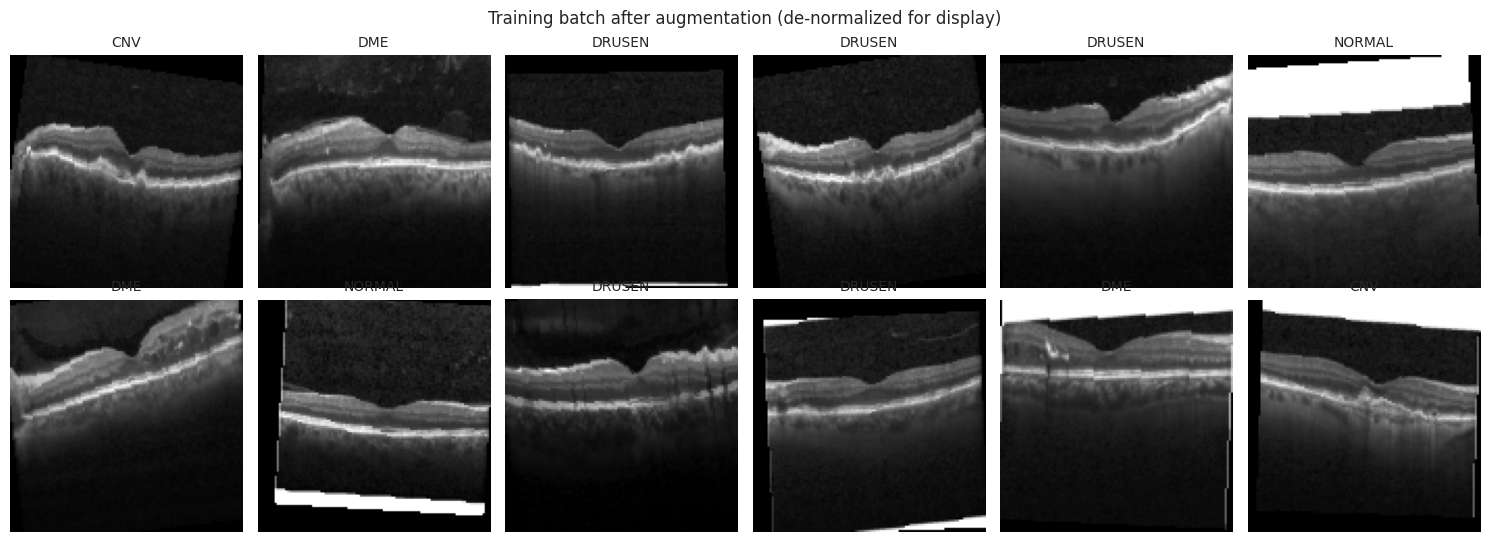

In [6]:
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

class OCTDataset(Dataset):
    """In-memory OCT dataset. Stored as grey uint8; augmentation runs on the grey image,
    then the channel is repeated 3 times and ImageNet-normalized (as in Step 2)."""
    def __init__(self, images, labels, transform=None):
        self.x = torch.from_numpy(images).unsqueeze(1)          # N x 1 x H x W, uint8
        self.y = torch.from_numpy(labels).long()
        self.transform = transform
    def __len__(self):
        return len(self.y)
    def __getitem__(self, i):
        x = self.x[i]
        if self.transform is not None:
            x = self.transform(x)
        x = (x.float() / 255.0).repeat(3, 1, 1)                  # 1 -> 3 channels
        return (x - IMAGENET_MEAN) / IMAGENET_STD, self.y[i]

train_tf = v2.Compose([
    v2.RandomHorizontalFlip(p=0.5),
    v2.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.9, 1.1)),
    v2.ColorJitter(brightness=0.2, contrast=0.2),
])

train_ds = OCTDataset(X_train, y_train, transform=train_tf)       # augmented: used for fine-tuning
train_plain_ds = OCTDataset(X_train, y_train)                     # no augmentation: used for feature extraction
val_ds, test_ds = OCTDataset(X_val, y_val), OCTDataset(X_test, y_test)

def make_loader(ds, batch_size, shuffle, seed=SEED):
    g = torch.Generator(); g.manual_seed(seed)
    # num_workers=0 avoids multiprocessing problems on Windows / Jupyter
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, num_workers=0, generator=g,
                      pin_memory=(device.type == "cuda"))

train_loader = make_loader(train_ds, BATCH_SIZE, True)
val_loader, test_loader = make_loader(val_ds, 64, False), make_loader(test_ds, 64, False)

xb, yb = next(iter(train_loader))
print("Batch:", tuple(xb.shape), xb.dtype, "| value range", f"{xb.min():.2f} to {xb.max():.2f}")

fig, axes = plt.subplots(2, 6, figsize=(15, 5.5))
for ax, img_t, lab in zip(axes.ravel(), xb[:12], yb[:12]):
    ax.imshow((img_t * IMAGENET_STD + IMAGENET_MEAN).clamp(0, 1)[0].numpy(), cmap="gray")
    ax.set_title(class_names[int(lab)], fontsize=10); ax.axis("off")
plt.suptitle("Training batch after augmentation (de-normalized for display)")
plt.tight_layout(); plt.show()

## 5.3 Load the four pretrained models and replace the final layer
Each ImageNet model ends in a layer with **1,000 outputs**. We replace only that layer with a new `Linear(..., 4)` that is randomly initialized; everything before it keeps its ImageNet weights.

In [7]:
ARCHS = ["resnet18", "vgg16", "mobilenet_v2", "densenet121"]

def head_module(m, arch):
    return {"resnet18": lambda: m.fc, "vgg16": lambda: m.classifier[6],
            "mobilenet_v2": lambda: m.classifier[1], "densenet121": lambda: m.classifier}[arch]()

def set_head(m, arch, new):
    if arch == "resnet18": m.fc = new
    elif arch == "vgg16": m.classifier[6] = new
    elif arch == "mobilenet_v2": m.classifier[1] = new
    elif arch == "densenet121": m.classifier = new

def last_block_modules(m, arch):
    """The last stage of the pretrained body (unfrozen in partial fine-tuning)."""
    return {"resnet18": lambda: [m.layer4], "vgg16": lambda: [m.features[24:]],             # conv block 5
            "mobilenet_v2": lambda: [m.features[14:]],                                       # last inverted-residual blocks
            "densenet121": lambda: [m.features.denseblock4, m.features.norm5]}[arch]()

def build_model(arch, replace_head=True):
    set_seed()
    m = getattr(models, arch)(weights="DEFAULT" if PRETRAINED else None)
    if replace_head:
        old = head_module(m, arch)
        set_head(m, arch, nn.Linear(old.in_features, n_classes))
    return m.to(device)

def count(m, only_trainable=False):
    return sum(p.numel() for p in m.parameters() if (p.requires_grad or not only_trainable))

rows = []
for arch in ARCHS:
    m = build_model(arch, replace_head=False)
    old = head_module(m, arch)
    set_head(m, arch, nn.Linear(old.in_features, n_classes))
    rows.append({"model": arch, "parameters (M)": count(m) / 1e6, "size (MB)": count(m) * 4 / 1e6,
                 "original final layer": f"Linear({old.in_features} -> {old.out_features})",
                 "new final layer": f"Linear({old.in_features} -> {n_classes})"})
    del m; gc.collect()
display(pd.DataFrame(rows).round(1))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 169MB/s]


Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:05<00:00, 94.4MB/s]


Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 127MB/s]


Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 108MB/s] 


,model,parameters (M),size (MB),original final layer,new final layer
0,resnet18,11.2,44.7,Linear(512 -> 1000),Linear(512 -> 4)
1,vgg16,134.3,537.1,Linear(4096 -> 1000),Linear(4096 -> 4)
2,mobilenet_v2,2.2,8.9,Linear(1280 -> 1000),Linear(1280 -> 4)
3,densenet121,7.0,27.8,Linear(1024 -> 1000),Linear(1024 -> 4)


## 5.4 Training and evaluation tools
- **Feature extraction** is done efficiently: the frozen body never changes, so we pass every scan through it **once**, keep the resulting feature vectors, and train only the new final layer on those (seconds instead of minutes). This uses no augmentation.
- **Fine-tuning** trains the unfrozen layers end to end with augmentation. The new layer gets a larger learning rate (1e-3) than the pretrained layers (1e-4), so pretrained knowledge is nudged, not erased.
- Frozen **BatchNorm** layers stay in evaluation mode, so their ImageNet statistics are not disturbed.
- The weights from the **best validation macro-F1** epoch are restored at the end.

In [8]:
def confusion(y_true, y_pred):
    cm = np.zeros((n_classes, n_classes), dtype=int)
    np.add.at(cm, (y_true, y_pred), 1)
    return cm

def macro_f1(cm):
    tp = np.diag(cm).astype(float)
    precision = tp / np.maximum(cm.sum(0), 1)
    recall = tp / np.maximum(cm.sum(1), 1)
    return float((2 * precision * recall / np.maximum(precision + recall, 1e-12)).mean())

def metrics_from_probs(probs, y):
    pred = probs.argmax(1)
    cm = confusion(y, pred)
    loss = float(-np.log(np.clip(probs[np.arange(len(y)), y], 1e-12, 1)).mean())
    return {"loss": loss, "acc": float((pred == y).mean()), "f1": macro_f1(cm), "cm": cm,
            "recall": (cm.diagonal() / cm.sum(1)).tolist(), "pred": pred, "probs": probs}

@torch.no_grad()
def predict(model, loader):
    model.eval()
    probs, ys = [], []
    for x, y in loader:
        probs.append(model(x.to(device)).softmax(1).cpu()); ys.append(y)
    return metrics_from_probs(torch.cat(probs).numpy(), torch.cat(ys).numpy())

def set_strategy(model, arch, strategy):
    for p in model.parameters():
        p.requires_grad = strategy == "full_ft"
    for p in head_module(model, arch).parameters():
        p.requires_grad = True
    if strategy == "partial_ft":
        for blk in last_block_modules(model, arch):
            for p in blk.parameters():
                p.requires_grad = True

def prepare_train_mode(model):
    model.train()
    for m in model.modules():                       # frozen BatchNorm keeps its ImageNet statistics
        if isinstance(m, nn.modules.batchnorm._BatchNorm) and not any(p.requires_grad for p in m.parameters()):
            m.eval()

def fit_finetune(model, arch, strategy, epochs, lr_head=1e-3, lr_backbone=1e-4, cosine=False, verbose=False):
    set_strategy(model, arch, strategy)
    head_params = list(head_module(model, arch).parameters())
    head_ids = {id(p) for p in head_params}
    body_params = [p for p in model.parameters() if p.requires_grad and id(p) not in head_ids]
    groups = [{"params": head_params, "lr": lr_head}] + ([{"params": body_params, "lr": lr_backbone}] if body_params else [])
    opt = torch.optim.AdamW(groups, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs) if cosine else None
    criterion = nn.CrossEntropyLoss()
    hist = {k: [] for k in ["train_loss", "train_acc", "val_loss", "val_acc", "val_f1"]}
    best_f1, best_state, t0 = -1.0, None, time.time()
    for ep in range(epochs):
        prepare_train_mode(model)
        loss_sum, correct, seen = 0.0, 0, 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
            loss_sum += loss.item() * len(y); correct += (out.argmax(1) == y).sum().item(); seen += len(y)
        if sched: sched.step()
        v = predict(model, val_loader)
        for k, val in zip(hist, [loss_sum / seen, correct / seen, v["loss"], v["acc"], v["f1"]]):
            hist[k].append(val)
        if verbose:
            print(f"epoch {ep + 1:2d} | train loss {hist['train_loss'][-1]:.4f} acc {hist['train_acc'][-1]:.3f} "
                  f"| val loss {v['loss']:.4f} acc {v['acc']:.3f} F1 {v['f1']:.3f} | {time.time() - t0:.0f}s")
        if v["f1"] > best_f1:
            best_f1, best_state = v["f1"], copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    hist["best_epoch"] = int(np.argmax(hist["val_f1"])) + 1
    hist["time"] = time.time() - t0
    return hist

@torch.no_grad()
def extract_features(arch, loaders):
    """Pass data once through the frozen pretrained body (final layer replaced by Identity)."""
    m = build_model(arch, replace_head=False)
    set_head(m, arch, nn.Identity())
    m.eval()
    out = []
    for loader in loaders:
        feats = torch.cat([m(x.to(device)).cpu() for x, _ in loader])
        out.append(feats)
    del m; gc.collect()
    return out

def fit_head(Ftr, ytr, Fva, yva, epochs, lr=1e-3, verbose=False):
    set_seed()
    head = nn.Linear(Ftr.shape[1], n_classes)
    mu, sd = Ftr.mean(0, keepdim=True), Ftr.std(0, keepdim=True) + 1e-6          # standardize features (train stats)
    norm = lambda f: (f - mu) / sd
    opt = torch.optim.AdamW(head.parameters(), lr=lr, weight_decay=1e-2)
    ytr_t = torch.from_numpy(ytr).long()
    hist = {k: [] for k in ["train_loss", "val_loss", "val_acc", "val_f1"]}
    best_f1, best_state, t0 = -1.0, None, time.time()
    g = torch.Generator(); g.manual_seed(SEED)
    for ep in range(epochs):
        head.train()
        order = torch.randperm(len(ytr_t), generator=g)
        loss_sum = 0.0
        for s in range(0, len(order), 128):
            b = order[s:s + 128]
            loss = F.cross_entropy(head(norm(Ftr[b])), ytr_t[b])
            opt.zero_grad(); loss.backward(); opt.step()
            loss_sum += loss.item() * len(b)
        head.eval()
        with torch.no_grad():
            v = metrics_from_probs(head(norm(Fva)).softmax(1).numpy(), yva)
        for k, val in zip(hist, [loss_sum / len(ytr_t), v["loss"], v["acc"], v["f1"]]):
            hist[k].append(val)
        if v["f1"] > best_f1:
            best_f1, best_state = v["f1"], copy.deepcopy(head.state_dict())
    head.load_state_dict(best_state)
    hist["best_epoch"] = int(np.argmax(hist["val_f1"])) + 1
    hist["time"] = time.time() - t0
    head.eval()
    def head_fn(F_):
        with torch.no_grad():
            return head(norm(F_)).softmax(1).numpy()
    return head_fn, hist, head.weight.numel() + head.bias.numel()

### Smoke test: does the replaced model run?
One forward pass of a real batch through a fresh ResNet18, and a check that the output has 4 scores per scan.

In [9]:
m = build_model("resnet18")
with torch.no_grad():
    out = m.eval()(xb.to(device))
print("Output shape:", tuple(out.shape), "(batch, 4 classes)")
print("Initial loss (random new head):", f"{F.cross_entropy(out, yb.to(device)).item():.3f}", "| ln 4 =", f"{np.log(4):.3f}")
del m; gc.collect()

Output shape: (32, 4) (batch, 4 classes)
Initial loss (random new head): 1.364 | ln 4 = 1.386


10

## 5.5 Experiment: all four architectures, feature extraction vs partial fine-tuning
For each architecture:
1. **Feature extraction:** frozen body, train only the new final layer.
2. **Partial fine-tuning:** also unfreeze the last block of the body (ResNet18 `layer4`, VGG16 conv block 5, MobileNetV2 last blocks, DenseNet121 `denseblock4`).

Full fine-tuning (all layers) is added in 5.8 for the best architecture, because it is the most expensive setting. Validation macro-F1 chooses the best epoch; the test split is evaluated once per finished run for the final comparison only.

In [10]:
results = []          # one row per (architecture, strategy)
histories = {}

def record(arch, strategy, hist, trainable, val_res, test_res):
    results.append({"model": arch, "strategy": strategy, "trainable params (M)": trainable / 1e6,
                    "val acc": val_res["acc"], "val macro-F1": val_res["f1"],
                    "test acc": test_res["acc"], "test macro-F1": test_res["f1"],
                    "best epoch": hist["best_epoch"], "train seconds": hist["time"],
                    "test recall": test_res["recall"], "test cm": test_res["cm"]})
    histories[(arch, strategy)] = hist

# --- feature extraction ---
if "feature_extraction" in STRATEGIES:
    plain_loaders = [make_loader(d, 64, False) for d in (train_plain_ds, val_ds, test_ds)]
    for arch in ARCHS:
        t0 = time.time()
        Ftr, Fva, Fte = extract_features(arch, plain_loaders)
        t_extract = time.time() - t0
        head_fn, hist, n_head = fit_head(Ftr, y_train, Fva, y_val, epochs=FE_EPOCHS)
        hist["time"] += t_extract
        val_res = metrics_from_probs(head_fn(Fva), y_val)
        test_res = metrics_from_probs(head_fn(Fte), y_test)
        record(arch, "feature_extraction", hist, n_head, val_res, test_res)
        print(f"{arch:13s} feature extraction | feature size {Ftr.shape[1]:5d} | val F1 {val_res['f1']:.3f} "
              f"| test acc {test_res['acc']:.3f} F1 {test_res['f1']:.3f} | {hist['time']:.0f}s")

resnet18      feature extraction | feature size   512 | val F1 0.730 | test acc 0.774 F1 0.770 | 3s
vgg16         feature extraction | feature size  4096 | val F1 0.658 | test acc 0.677 F1 0.677 | 10s
mobilenet_v2  feature extraction | feature size  1280 | val F1 0.727 | test acc 0.819 F1 0.818 | 3s
densenet121   feature extraction | feature size  1024 | val F1 0.800 | test acc 0.847 F1 0.845 | 5s


In [11]:
# --- partial fine-tuning (and full fine-tuning too when QUICK_MODE = False) ---
for strategy in [s for s in STRATEGIES if s != "feature_extraction"]:
    for arch in ARCHS:
        model = build_model(arch)
        hist = fit_finetune(model, arch, strategy, epochs=FT_EPOCHS)
        trainable = count(model, only_trainable=True)
        val_res, test_res = predict(model, val_loader), predict(model, test_loader)
        record(arch, strategy, hist, trainable, val_res, test_res)
        print(f"{arch:13s} {strategy:11s} | trainable {trainable / 1e6:6.2f} M | val F1 {val_res['f1']:.3f} "
              f"| test acc {test_res['acc']:.3f} F1 {test_res['f1']:.3f} | {hist['time']:.0f}s")
        del model; gc.collect()
        if device.type == "cuda": torch.cuda.empty_cache()

resnet18      partial_ft  | trainable   8.40 M | val F1 0.765 | test acc 0.814 F1 0.810 | 12s
vgg16         partial_ft  | trainable   7.10 M | val F1 0.822 | test acc 0.835 F1 0.834 | 18s
mobilenet_v2  partial_ft  | trainable   1.69 M | val F1 0.822 | test acc 0.888 F1 0.885 | 11s
densenet121   partial_ft  | trainable   2.16 M | val F1 0.744 | test acc 0.767 F1 0.757 | 15s


,model,strategy,trainable params (M),val macro-F1,test acc,test macro-F1,best epoch,train seconds
0,vgg16,partial_ft,7.096,0.822,0.835,0.834,3,18.223
1,mobilenet_v2,partial_ft,1.686,0.822,0.888,0.885,3,10.950
2,densenet121,feature_extraction,0.004,0.800,0.847,0.845,35,4.543
3,resnet18,partial_ft,8.396,0.765,0.814,0.810,3,12.101
4,densenet121,partial_ft,2.164,0.744,0.767,0.757,2,14.965
5,resnet18,feature_extraction,0.002,0.730,0.774,0.770,38,2.812
6,mobilenet_v2,feature_extraction,0.005,0.727,0.819,0.818,5,3.006
7,vgg16,feature_extraction,0.016,0.658,0.677,0.677,6,9.639


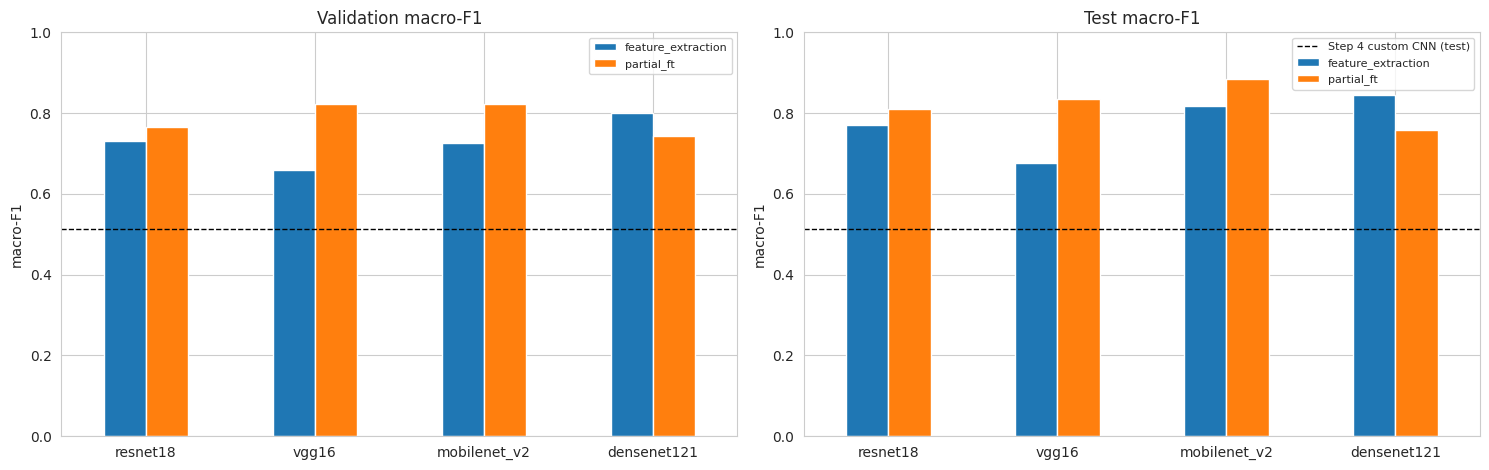

In [12]:
res_df = pd.DataFrame(results)
show = ["model", "strategy", "trainable params (M)", "val macro-F1", "test acc", "test macro-F1", "best epoch", "train seconds"]
display(res_df[show].sort_values("val macro-F1", ascending=False).round(3).reset_index(drop=True))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for ax, col, title in zip(axes, ["val macro-F1", "test macro-F1"], ["Validation macro-F1", "Test macro-F1"]):
    pivot = res_df.pivot(index="model", columns="strategy", values=col).reindex(ARCHS)
    pivot.plot.bar(ax=ax, rot=0)
    ax.set_title(title); ax.set_ylabel("macro-F1"); ax.set_xlabel(""); ax.set_ylim(0, 1)
    ax.axhline(0.512, color="k", ls="--", lw=1, label="Step 4 custom CNN (test)" if col.startswith("test") else None)
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**What to look for:** the dashed line is the Step 4 custom CNN's test macro-F1 (0.512 from your Step 4 run). It used a different, much smaller setup, so read it as a rough reference, not a controlled comparison. Compare feature extraction with partial fine-tuning for each model: if fine-tuning helps a lot, ImageNet features alone do not capture OCT-specific structure. Differences of a few hundredths between models are within noise on one seed.

### Learning curves (fine-tuning runs)

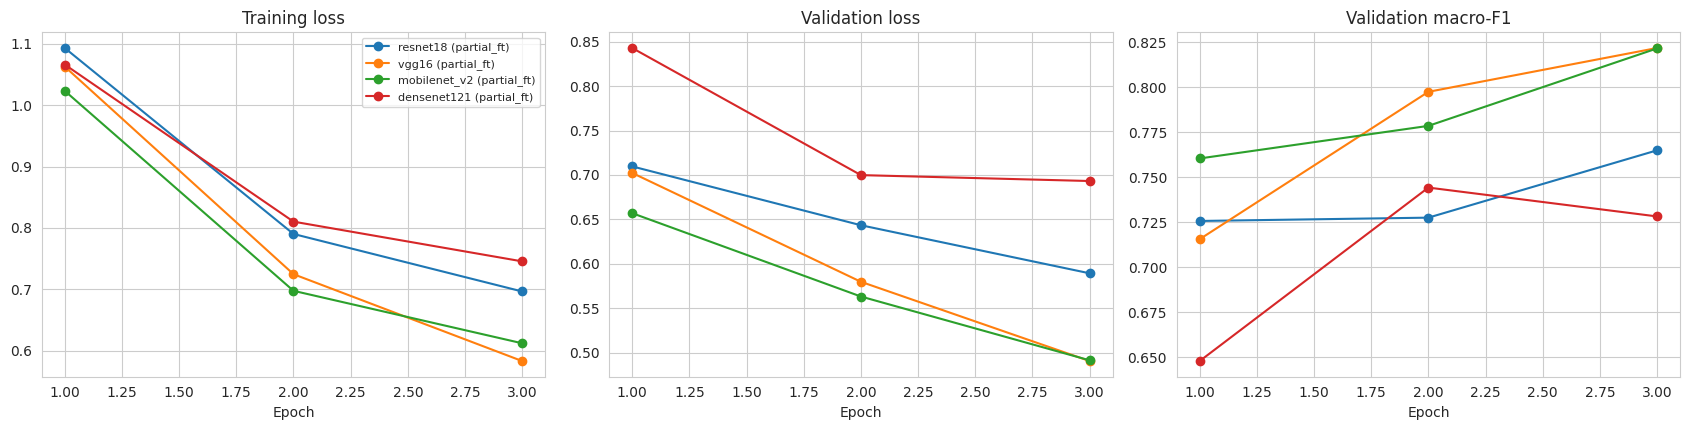

In [13]:
ft_keys = [k for k in histories if k[1] != "feature_extraction"]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
for k in ft_keys:
    h = histories[k]
    axes[0].plot(range(1, len(h["train_loss"]) + 1), h["train_loss"], marker="o", label=f"{k[0]} ({k[1]})")
    axes[1].plot(range(1, len(h["val_loss"]) + 1), h["val_loss"], marker="o", label=f"{k[0]} ({k[1]})")
    axes[2].plot(range(1, len(h["val_f1"]) + 1), h["val_f1"], marker="o", label=f"{k[0]} ({k[1]})")
for ax, t in zip(axes, ["Training loss", "Validation loss", "Validation macro-F1"]):
    ax.set_title(t); ax.set_xlabel("Epoch")
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 5.6 Compare the architectures: accuracy, size and speed
Accuracy is only one criterion. In a clinic, model size and prediction speed matter too. We time inference for each architecture (batch of 32 scans at the current image size, after a warm-up).

,parameters (M),size (MB),inference (ms / scan),best strategy (val),val macro-F1,test acc,test macro-F1
resnet18,11.179,44.714,0.439,partial_ft,0.765,0.814,0.810
vgg16,134.277,537.108,1.648,partial_ft,0.822,0.835,0.834
mobilenet_v2,2.229,8.916,0.205,partial_ft,0.822,0.888,0.885
densenet121,6.958,27.832,0.750,feature_extraction,0.800,0.847,0.845


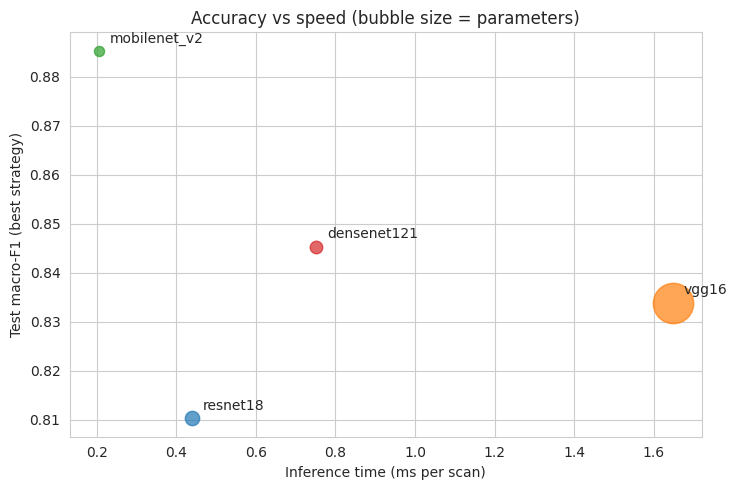

In [14]:
@torch.no_grad()
def time_inference(arch, batch=32, reps=3):
    m = build_model(arch).eval()
    x = torch.randn(batch, 3, IMG_SIZE, IMG_SIZE, device=device)
    m(x)                                                          # warm-up
    if device.type == "cuda": torch.cuda.synchronize()
    t0 = time.time()
    for _ in range(reps):
        m(x)
    if device.type == "cuda": torch.cuda.synchronize()
    ms = (time.time() - t0) / (reps * batch) * 1000
    n = count(m); del m; gc.collect()
    return n, ms

speed = {a: time_inference(a) for a in ARCHS}
best_per_arch = res_df.sort_values("val macro-F1", ascending=False).groupby("model").first().reindex(ARCHS)
compare = pd.DataFrame({
    "parameters (M)": [speed[a][0] / 1e6 for a in ARCHS],
    "size (MB)": [speed[a][0] * 4 / 1e6 for a in ARCHS],
    "inference (ms / scan)": [speed[a][1] for a in ARCHS],
    "best strategy (val)": best_per_arch["strategy"].values,
    "val macro-F1": best_per_arch["val macro-F1"].values,
    "test acc": best_per_arch["test acc"].values,
    "test macro-F1": best_per_arch["test macro-F1"].values,
}, index=ARCHS)
display(compare.round(3))

fig, ax = plt.subplots(figsize=(7.5, 5))
for a in ARCHS:
    ax.scatter(compare.loc[a, "inference (ms / scan)"], compare.loc[a, "test macro-F1"],
               s=40 + 6 * compare.loc[a, "parameters (M)"], alpha=0.7)
    ax.annotate(a, (compare.loc[a, "inference (ms / scan)"], compare.loc[a, "test macro-F1"]),
                textcoords="offset points", xytext=(8, 6))
ax.set_xlabel("Inference time (ms per scan)"); ax.set_ylabel("Test macro-F1 (best strategy)")
ax.set_title("Accuracy vs speed (bubble size = parameters)")
plt.tight_layout(); plt.show()

**What to look for:** VGG16 has the most parameters and is usually the slowest, MobileNetV2 the smallest and often the fastest. A model that is nearly as accurate but several times smaller or faster can be the better practical choice.

## 5.7 Per-class recall of every run
The earlier steps showed that accuracy can hide a class the model never predicts. This table shows the recall for each class on the test split.

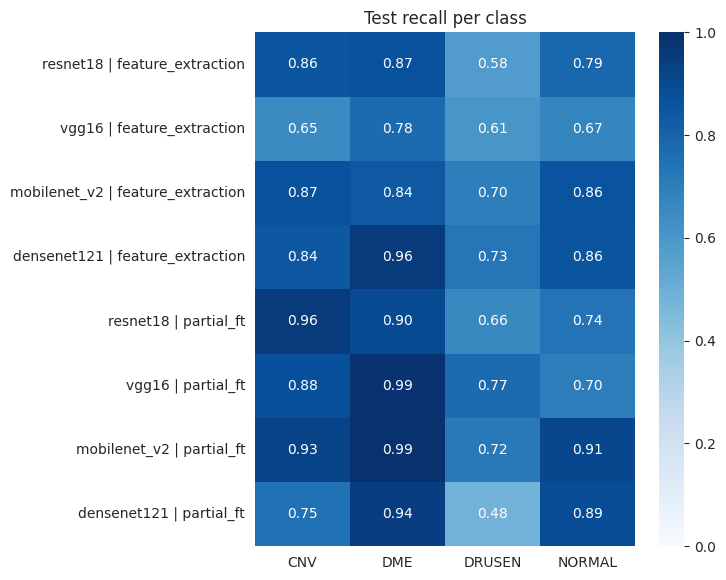

In [15]:
recall_df = pd.DataFrame([r["test recall"] for r in results], columns=class_names,
                         index=[f"{r['model']} | {r['strategy']}" for r in results])
plt.figure(figsize=(7.5, 0.55 * len(recall_df) + 1.5))
sns.heatmap(recall_df, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
plt.title("Test recall per class"); plt.ylabel("")
plt.tight_layout(); plt.show()

## 5.8 Final model: full fine-tuning of the best architecture
The architecture with the highest validation macro-F1 gets **full fine-tuning** (all layers, cosine learning-rate schedule). If full fine-tuning was already run in 5.5 (`QUICK_MODE = False`), the single best run overall is used instead. The result is judged once on the untouched test split.

In [16]:
best_row = res_df.sort_values("val macro-F1", ascending=False).iloc[0]
best_arch = best_row["model"]
print(f"Best architecture by validation macro-F1: {best_arch} ({best_row['strategy']}, val F1 {best_row['val macro-F1']:.3f})")

if best_row["strategy"] == "full_ft" or not QUICK_MODE:
    final_arch, final_strategy = best_arch, best_row["strategy"]
    print("Full fine-tuning was already part of the comparison; re-training the best run for the final report.")
else:
    final_arch, final_strategy = best_arch, "full_ft"

final_model = build_model(final_arch)
final_hist = fit_finetune(final_model, final_arch, final_strategy, epochs=FINAL_EPOCHS, cosine=True, verbose=True)
print(f"\nbest epoch {final_hist['best_epoch']} | {final_hist['time'] / 60:.1f} min")

Best architecture by validation macro-F1: vgg16 (partial_ft, val F1 0.822)
epoch  1 | train loss 1.0291 acc 0.545 | val loss 0.8266 acc 0.767 F1 0.756 | 14s
epoch  2 | train loss 0.5637 acc 0.795 | val loss 0.4349 acc 0.844 F1 0.843 | 28s
epoch  3 | train loss 0.3741 acc 0.874 | val loss 0.3164 acc 0.892 F1 0.890 | 41s
epoch  4 | train loss 0.2849 acc 0.900 | val loss 0.3574 acc 0.886 F1 0.883 | 55s
epoch  5 | train loss 0.2401 acc 0.911 | val loss 0.2780 acc 0.900 F1 0.899 | 69s
epoch  6 | train loss 0.1884 acc 0.935 | val loss 0.2753 acc 0.908 F1 0.908 | 82s

best epoch 6 | 1.4 min


Final model: vgg16 (full_ft)
Validation: acc 0.908 | macro-F1 0.908
Test:       acc 0.962 | macro-F1 0.962 | CE loss 0.140
Step 4 custom CNN (your run, 64x64): test acc 0.597 | macro-F1 0.512


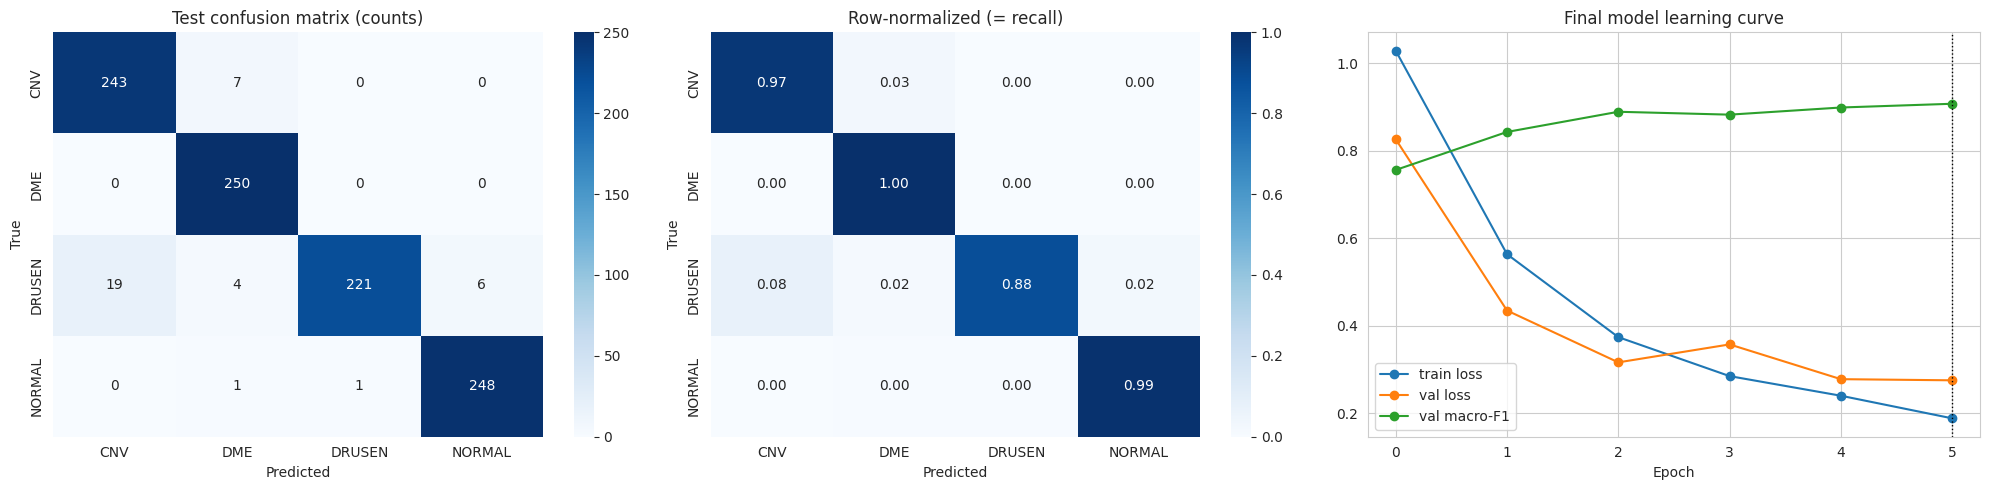

,class,recall,precision,F1,test scans
0,CNV,0.972,0.927,0.949,250
1,DME,1.000,0.954,0.977,250
2,DRUSEN,0.884,0.995,0.936,250
3,NORMAL,0.992,0.976,0.984,250


In [17]:
val_res, test_res = predict(final_model, val_loader), predict(final_model, test_loader)
print(f"Final model: {final_arch} ({final_strategy})")
print(f"Validation: acc {val_res['acc']:.3f} | macro-F1 {val_res['f1']:.3f}")
print(f"Test:       acc {test_res['acc']:.3f} | macro-F1 {test_res['f1']:.3f} | CE loss {test_res['loss']:.3f}")
print(f"Step 4 custom CNN (your run, 64x64): test acc 0.597 | macro-F1 0.512")

cm = test_res["cm"]
recall = cm.diagonal() / cm.sum(1)
precision = cm.diagonal() / np.maximum(cm.sum(0), 1)
f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-12)

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("True"); axes[0].set_title("Test confusion matrix (counts)")
sns.heatmap(cm / cm.sum(1, keepdims=True), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
            xticklabels=class_names, yticklabels=class_names, ax=axes[1])
axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("True"); axes[1].set_title("Row-normalized (= recall)")
axes[2].plot(final_hist["train_loss"], marker="o", label="train loss")
axes[2].plot(final_hist["val_loss"], marker="o", label="val loss")
axes[2].plot(final_hist["val_f1"], marker="o", label="val macro-F1")
axes[2].axvline(final_hist["best_epoch"] - 1, color="k", ls=":", lw=1)
axes[2].set_xlabel("Epoch"); axes[2].set_title("Final model learning curve"); axes[2].legend()
plt.tight_layout(); plt.show()

display(pd.DataFrame({"class": class_names, "recall": recall, "precision": precision, "F1": f1,
                      "test scans": cm.sum(1)}).round(3))

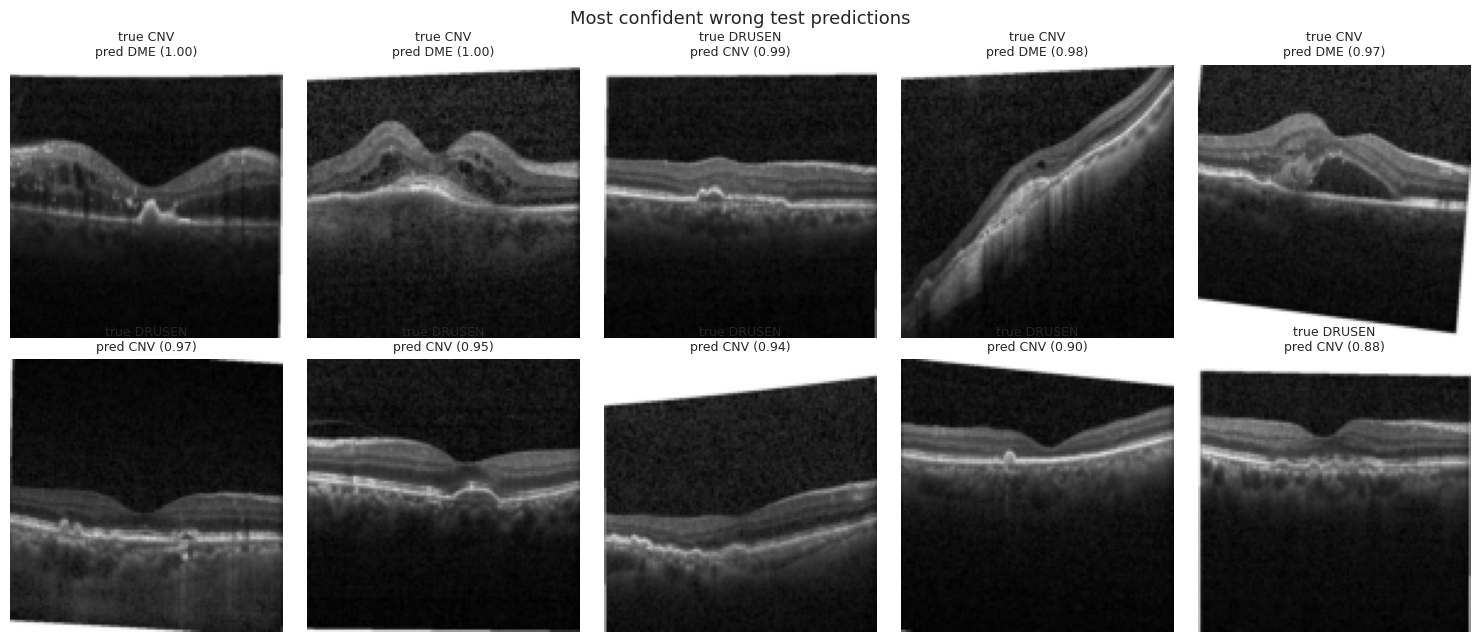

38 of 1000 test scans misclassified


In [18]:
wrong = np.where(test_res["pred"] != y_test)[0]
conf = test_res["probs"].max(1)[wrong]
show = wrong[np.argsort(-conf)][:10]            # the most confident wrong predictions
fig, axes = plt.subplots(2, 5, figsize=(15, 6.5))
for ax, i in zip(axes.ravel(), show):
    ax.imshow(X_test[i], cmap="gray")
    ax.set_title(f"true {class_names[y_test[i]]}\npred {class_names[test_res['pred'][i]]} ({test_res['probs'][i].max():.2f})", fontsize=9)
    ax.axis("off")
plt.suptitle("Most confident wrong test predictions", fontsize=13)
plt.tight_layout(); plt.show()
print(f"{len(wrong)} of {len(y_test)} test scans misclassified")

### Save the best model and settings for later steps

In [19]:
torch.save(final_model.state_dict(), "step5_best_transfer_model.pt")
res_df.drop(columns=["test recall", "test cm"]).to_csv("step5_architecture_comparison.csv", index=False)
config5 = {
    "architecture": final_arch, "strategy": final_strategy, "pretrained_weights": "ImageNet (torchvision DEFAULT)" if PRETRAINED else "none",
    "img_size": IMG_SIZE, "channels": 3, "norm_mean": IMAGENET_MEAN.flatten().tolist(), "norm_std": IMAGENET_STD.flatten().tolist(),
    "class_names": class_names, "per_class_train_scans": PER_CLASS, "quick_mode": QUICK_MODE,
    "val_accuracy": val_res["acc"], "val_macro_f1": val_res["f1"],
    "test_accuracy": test_res["acc"], "test_macro_f1": test_res["f1"], "seed": SEED,
}
with open("transfer_learning_config.json", "w") as f:
    json.dump(config5, f, indent=2)
print("Saved step5_best_transfer_model.pt, step5_architecture_comparison.csv and transfer_learning_config.json")

Saved step5_best_transfer_model.pt, step5_architecture_comparison.csv and transfer_learning_config.json


## Summary of Step 5
- Explained why transfer learning helps with small medical image sets, and what can go wrong (ImageNet is colour photos).
- Loaded **ResNet18, VGG16, MobileNetV2 and DenseNet121** with ImageNet weights and replaced each 1,000-way final layer with a 4-way layer.
- Compared **feature extraction** (train only the new layer) with **partial fine-tuning** (also the last block), and ran **full fine-tuning** on the best architecture.
- Compared the architectures on validation and test macro-F1, per-class recall, parameter count and inference speed.
- Used a **balanced** training pool so that no class (DRUSEN in Step 4) is ignored.
